# 04 - Baseline model v2: low-water-aware

`03. baseline_model.ipynb` reports a linear AR model beating persistence at a 7-day horizon
(MAE 49.0 vs 50.8, skill 0.149). Broken down by water-level regime on the same test set, that
headline reverses where it matters:

| target level | n | MAE persistence | MAE linear AR | bias AR |
|---|---|---|---|---|
| <= 78 cm | 57 | **23.5** | 46.7 | -45.4 |
| 78-100 | 58 | **18.0** | 42.8 | -42.8 |
| 100-150 | 292 | **26.1** | 34.3 | -32.5 |
| 150-250 | 352 | 50.1 | **37.5** | -13.2 |
| 250-400 | 258 | 70.1 | **57.1** | +30.3 |
| > 400 | 72 | **133.6** | 143.2 | +131.9 |

Persistence wins every bin below 150 cm - 407 of 1089 test days - and the AR model
over-predicts low water by about 45 cm, the worst possible direction for load planning. This
is structural, not overfitting: in-sample below 78 cm the same gap appears (persistence 13.2,
AR 42.9). Ordinary least squares minimises global MSE over a target whose spread is dominated
by high flows, so it pulls low values toward the mean.

**What this notebook changes**

1. **Evaluate by regime, always.** A single aggregate MAE is not an acceptable summary for
   this problem; every model is reported with a low-water column and a full regime table.
2. **Model `log10(level)`.** A multiplicative error scale makes a 20 cm miss at 40 cm count
   far more than a 20 cm miss at 400 cm, which is the actual cost structure.
3. **Add the physical driver.** Cumulative precipitation over the window `02. eda.ipynb`
   identified (30 days, r = 0.53), plus temperature, snowpack proxy and seasonality.
4. **Fix the mechanical defects in 03** - the stale-`df` cell ordering, the hardcoded
   `parse_dates=["date"]` beside a configurable `DATE_COL`, and the positional skill-score
   assignment.

The train/test protocol from 03 is kept unchanged - it was correct.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

DAILY_PATH = "../data/processed/kaub_water_weather_daily.csv"
HOURLY_PATH = "../data/processed/kaub_water_weather_hourly.csv"

DATE_COL = "date"
LEVEL_COL = "water_level_mean"

HORIZON = 7        # forecast this many days ahead
TEST_YEARS = 3     # hold out the most recent N years
VAL_YEARS = 3      # carve this many years off the end of train for model selection

# Placeholder operating threshold - replace with the operator's actual loading limit.
LOW_WATER_CM = 78

# Regime edges used for every breakdown in this notebook.
REGIME_BINS = [0, 78, 100, 150, 250, 400, np.inf]

RANDOM_STATE = 0

## 1. Load and validate

Note `parse_dates=[DATE_COL]` rather than a hardcoded `"date"`: in 03 the constant was
presented as configurable but the read ignored it, so changing it would silently leave the
column as a string.

In [2]:
df = pd.read_csv(DAILY_PATH, parse_dates=[DATE_COL])
print("shape:", df.shape)
df.head()

shape: (9741, 11)


,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean
0,2000-01-01,438.989130,420.75,458.25,3.286957,97.434783,1.7,1.7,0.0,1025.256522,7.773913
1,2000-01-02,401.260417,385.25,419.00,3.979167,96.291667,0.0,0.0,0.0,1030.475000,6.095833
2,2000-01-03,367.989583,359.25,383.50,2.350000,94.458333,0.0,0.0,0.0,1028.470833,11.875000
3,2000-01-04,346.093750,337.00,358.75,5.470833,91.791667,0.8,0.8,0.0,1020.412500,18.445833
4,2000-01-05,327.968750,320.00,337.00,5.495833,89.708333,0.2,0.2,0.0,1021.983333,10.237500


### 1.1 Drop the partial day

`02. eda.ipynb` established that 2000-01-01 aggregates only 23 hours - both sources start at
01:00 - so its mean and its `precipitation_sum` are not comparable to any other row. The lag
warm-up in 03 happened to discard it by accident; do it deliberately instead, because it stops
being accidental as soon as the feature set changes.

In [3]:
hours_per_day = (
    pd.read_csv(HOURLY_PATH, usecols=[DATE_COL])
      .groupby(DATE_COL)
      .size()
      .rename("hours_available")
)
hours_per_day.index = pd.to_datetime(hours_per_day.index)

df = df.merge(hours_per_day, left_on=DATE_COL, right_index=True, how="left")
incomplete = df.loc[df["hours_available"] != 24, DATE_COL].dt.date.tolist()
print("incomplete days dropped:", incomplete)

df = df.loc[df["hours_available"] == 24].drop(columns="hours_available")
df = df.sort_values(DATE_COL).drop_duplicates(subset=[DATE_COL], keep="last")
df = df.set_index(DATE_COL).asfreq("D")   # explicit NaN for any absent calendar day

print(f"{df.index.min().date()} -> {df.index.max().date()}  ({len(df)} days)")
print("absent calendar days:", int(df[LEVEL_COL].isna().sum()))
assert df.index.is_monotonic_increasing and df.index.is_unique

incomplete days dropped: [datetime.date(2000, 1, 1)]
2000-01-02 -> 2026-09-01  (9740 days)
absent calendar days: 0


## 2. Features

Every feature must be computable from information available **on day t**, for a target on day
`t + HORIZON`. Rolling windows therefore use only trailing data and are never centred, and
nothing is shifted by a negative amount except the target itself.

In [4]:
level = df[LEVEL_COL]

X = pd.DataFrame(index=df.index)

# --- autoregressive level history (this is the whole of the 03 feature set) ---
AR_LAGS = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28]
for L in AR_LAGS:
    X[f"lag_{L}"] = level.shift(L)
AR_FEATURES = [f"lag_{L}" for L in AR_LAGS]

# --- recession dynamics: how fast is the level already moving? ---
for w in (1, 3, 7, 14):
    X[f"diff_{w}d"] = level.diff(w)
for w in (7, 30, 90):
    X[f"level_mean_{w}d"] = level.rolling(w).mean()
X["level_std_30d"] = level.rolling(30).std()

# --- catchment storage: cumulative precipitation (02. eda found 30d optimal, r = 0.53) ---
for w in (7, 30, 90, 180):
    X[f"precip_sum_{w}d"] = df["precipitation_sum"].rolling(w).sum()
X["snow_sum_30d"] = df["snowfall_sum"].rolling(30).sum()
X["snow_sum_90d"] = df["snowfall_sum"].rolling(90).sum()

# --- evaporative demand and synoptic state ---
X["temp_mean_30d"] = df["temperature_mean"].rolling(30).mean()
X["temp_mean_90d"] = df["temperature_mean"].rolling(90).mean()
X["humidity_mean_30d"] = df["humidity_mean"].rolling(30).mean()
X["pressure_mean_7d"] = df["pressure_mean"].rolling(7).mean()

# --- seasonality as a smooth pair, not a month dummy ---
doy = df.index.dayofyear.to_numpy()
X["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
X["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

FULL_FEATURES = X.columns.tolist()
print(f"{len(FULL_FEATURES)} features ({len(AR_FEATURES)} of them the 03 AR set)")
print(FULL_FEATURES)

31 features (11 of them the 03 AR set)
['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'diff_1d', 'diff_3d', 'diff_7d', 'diff_14d', 'level_mean_7d', 'level_mean_30d', 'level_mean_90d', 'level_std_30d', 'precip_sum_7d', 'precip_sum_30d', 'precip_sum_90d', 'precip_sum_180d', 'snow_sum_30d', 'snow_sum_90d', 'temp_mean_30d', 'temp_mean_90d', 'humidity_mean_30d', 'pressure_mean_7d', 'doy_sin', 'doy_cos']


In [5]:
y = level.shift(-HORIZON).rename("target")
data = X.join(y).dropna()
print("rows after warm-up and target trim:", len(data))
print(f"{data.index.min().date()} -> {data.index.max().date()}")

rows after warm-up and target trim: 9554
2000-06-29 -> 2026-08-25


### 2.1 Causality check

03 asserted `target == s.iloc[i + H]`, which was the right instinct. Extend it: verify that
every engineered feature on a sample row is reproducible from the level and weather series
truncated at day t, with nothing after day t visible.

In [6]:
probe = data.index[4000]
past_level = level.loc[:probe]
past_df = df.loc[:probe]

recomputed = {
    "lag_0": past_level.iloc[-1],
    "lag_7": past_level.iloc[-8],
    "diff_7d": past_level.iloc[-1] - past_level.iloc[-8],
    "level_mean_30d": past_level.iloc[-30:].mean(),
    "precip_sum_30d": past_df["precipitation_sum"].iloc[-30:].sum(),
    "temp_mean_90d": past_df["temperature_mean"].iloc[-90:].mean(),
}
for name, value in recomputed.items():
    assert np.isclose(data.loc[probe, name], value), name
print(f"all {len(recomputed)} probed features on {probe.date()} use only data <= {probe.date()}")

assert np.isclose(data.loc[probe, "target"], level.loc[probe + pd.Timedelta(days=HORIZON)])
print(f"target on {probe.date()} == level on "
      f"{(probe + pd.Timedelta(days=HORIZON)).date()} = {data.loc[probe, 'target']:.2f} cm")

all 6 probed features on 2011-06-12 use only data <= 2011-06-12
target on 2011-06-12 == level on 2011-06-19 = 134.39 cm


## 3. Chronological split with embargo

Unchanged from 03, which had this right. The last training row's target lands on `split_date`
and the first test row is the day after, so no training target falls inside the test period.
A validation block is carved off the end of training the same way, so model selection never
touches the test set.

In [7]:
split_date = data.index.max() - pd.DateOffset(years=TEST_YEARS)
val_date = split_date - pd.DateOffset(years=VAL_YEARS)

test = data.loc[split_date + pd.Timedelta(days=1):]
val = data.loc[val_date + pd.Timedelta(days=1): split_date - pd.Timedelta(days=HORIZON)]
train = data.loc[: val_date - pd.Timedelta(days=HORIZON)]
train_full = data.loc[: split_date - pd.Timedelta(days=HORIZON)]   # train + val, for refit

for name, part in [("train", train), ("val", val), ("train_full", train_full), ("test", test)]:
    print(f"{name:11s}: {part.index.min().date()} -> {part.index.max().date()}  n={len(part)}")

assert train.index.max() + pd.Timedelta(days=HORIZON) < val.index.min(), "train/val embargo"
assert train_full.index.max() + pd.Timedelta(days=HORIZON) < test.index.min(), "test embargo"
print()
print(f"train_full target range: {train_full['target'].min():.1f} .. {train_full['target'].max():.1f} cm")
print(f"test       target range: {test['target'].min():.1f} .. {test['target'].max():.1f} cm")
print(f"test days below anything ever seen in training: "
      f"{int((test['target'] < train_full['target'].min()).sum())}")

train      : 2000-06-29 -> 2020-08-18  n=7356
val        : 2020-08-26 -> 2023-08-18  n=1088
train_full : 2000-06-29 -> 2023-08-18  n=8451
test       : 2023-08-26 -> 2026-08-25  n=1096

train_full target range: 25.3 .. 718.1 cm
test       target range: 6.4 .. 644.7 cm
test days below anything ever seen in training: 15


The last line matters for how the results are read. The test window contains the August 2026
record low, so a handful of test days sit below the training minimum entirely. Every model
below is extrapolating there, and none of them can be trusted in that range on the strength of
this evaluation alone.

## 4. Evaluation harness

Three deliberate choices:

- **Low-water metrics sit next to the aggregate**, never behind it.
- **Skill is computed from the results frame by name**, not assigned positionally as in 03,
  where adding a third model would have silently mislabelled every score.
- **Bias is reported per regime.** A model that is right on average by cancelling a +130 cm
  flood bias against a -45 cm low-water bias is not right.

In [8]:
def score(y_true: pd.Series, y_pred: pd.Series, name: str) -> pd.Series:
    err = y_true - y_pred
    low = y_true < LOW_WATER_CM
    return pd.Series({
        "MAE": err.abs().mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "bias": err.mean(),
        f"MAE_below_{LOW_WATER_CM}": err[low].abs().mean(),
        f"bias_below_{LOW_WATER_CM}": err[low].mean(),
        "n_low": int(low.sum()),
    }, name=name)


def leaderboard(preds: dict, y_true: pd.Series, reference: str = "persistence") -> pd.DataFrame:
    out = pd.concat([score(y_true, p, n) for n, p in preds.items()], axis=1).T
    ref_mse = out.loc[reference, "RMSE"] ** 2
    ref_low = out.loc[reference, f"MAE_below_{LOW_WATER_CM}"]
    out["skill_vs_ref"] = 1 - (out["RMSE"] ** 2) / ref_mse
    out[f"skill_below_{LOW_WATER_CM}"] = 1 - out[f"MAE_below_{LOW_WATER_CM}"] / ref_low
    return out


def regime_table(preds: dict, y_true: pd.Series, metric: str = "MAE") -> pd.DataFrame:
    bins = pd.cut(y_true, REGIME_BINS)
    rows = {}
    for name, pred in preds.items():
        err = y_true - pred
        grouped = err.groupby(bins, observed=True)
        rows[name] = grouped.apply(
            (lambda e: e.abs().mean()) if metric == "MAE" else (lambda e: e.mean())
        )
    out = pd.DataFrame(rows)
    out.insert(0, "n", y_true.groupby(bins, observed=True).size())
    return out

## 5. Models

`persistence` and `linear_ar` reproduce 03 exactly so the comparison is like for like. The new
entries differ in one dimension at a time: feature set, then target transform, then model
class.

Back-transforming a log-scale prediction with `10 ** p` returns a conditional *median*, not a
mean, so it under-predicts systematically. Duan's smearing estimator corrects that using the
training residuals, and is applied to both log models below.

In [9]:
X_tr, y_tr = train_full[FULL_FEATURES], train_full["target"]
X_te, y_te = test[FULL_FEATURES], test["target"]

preds = {}

# --- 0. persistence: tomorrow-plus-7 is today ---
preds["persistence"] = X_te["lag_0"].rename("persistence")

# --- 1. exactly the 03 model: OLS on level lags, raw target ---
ar = LinearRegression().fit(train_full[AR_FEATURES], y_tr)
preds["linear_ar"] = pd.Series(ar.predict(test[AR_FEATURES]), index=X_te.index)

# --- 2. same model class, full feature set ---
lin = LinearRegression().fit(X_tr, y_tr)
preds["linear_full"] = pd.Series(lin.predict(X_te), index=X_te.index)


def fit_log(model, X_fit, y_fit, X_pred):
    """Fit on log10(y) and back-transform with Duan's smearing factor."""
    y_log = np.log10(y_fit)
    model.fit(X_fit, y_log)
    residuals = y_log - model.predict(X_fit)
    smearing = np.mean(10 ** residuals)
    return pd.Series(10 ** model.predict(X_pred) * smearing, index=X_pred.index), smearing


# --- 3. log target, linear ---
preds["log_linear"], smear_lin = fit_log(LinearRegression(), X_tr, y_tr, X_te)
print(f"smearing factor, linear: {smear_lin:.4f}")

smearing factor, linear: 1.0457


### 5.1 Gradient boosting: hyperparameters chosen on the validation block

Selected on **validation low-water MAE**, not aggregate MAE - picking on the aggregate is how
03's result came about in the first place. The test set is untouched until section 6.

In [10]:
CANDIDATES = [
    {"learning_rate": 0.03, "max_iter": 400, "max_depth": 4},
    {"learning_rate": 0.05, "max_iter": 300, "max_depth": 6},
    {"learning_rate": 0.10, "max_iter": 200, "max_depth": 6},
]

rows = []
for params in CANDIDATES:
    model = HistGradientBoostingRegressor(
        early_stopping=False, random_state=RANDOM_STATE, **params
    )
    p_val, _ = fit_log(model, train[FULL_FEATURES], train["target"], val[FULL_FEATURES])
    rows.append({**params, **score(val["target"], p_val, "hgb").to_dict()})

selection = pd.DataFrame(rows)
display(selection.round(3))

best = selection.loc[selection[f"MAE_below_{LOW_WATER_CM}"].idxmin(), list(CANDIDATES[0])].to_dict()
best = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in best.items()}
print("selected on validation low-water MAE:", best)

,learning_rate,max_iter,max_depth,MAE,RMSE,bias,MAE_below_78,bias_below_78,n_low
0,0.03,400,4,46.450,65.855,-3.977,29.271,-29.271,55.0
1,0.05,300,6,48.768,70.958,-1.161,34.529,-34.529,55.0
2,0.10,200,6,49.862,72.684,-1.186,34.526,-34.526,55.0


selected on validation low-water MAE: {'learning_rate': 0.03, 'max_iter': 400, 'max_depth': 4}


In [11]:
hgb = HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE, **best)
preds["hgb_log"], smear_hgb = fit_log(hgb, X_tr, y_tr, X_te)
print(f"smearing factor, HGB: {smear_hgb:.4f}")
print("models evaluated:", list(preds))

smearing factor, HGB: 1.0196
models evaluated: ['persistence', 'linear_ar', 'linear_full', 'log_linear', 'hgb_log']


## 6. Results

In [12]:
board = leaderboard(preds, y_te)
print(f"Horizon: {HORIZON} days   |   test n = {len(y_te)}   |   "
      f"low-water days (< {LOW_WATER_CM} cm): {int((y_te < LOW_WATER_CM).sum())}")
board.round(3)

Horizon: 7 days   |   test n = 1096   |   low-water days (< 78 cm): 57


,MAE,RMSE,bias,MAE_below_78,bias_below_78,n_low,skill_vs_ref,skill_below_78
persistence,51.013,72.600,-0.773,23.471,-7.488,57.0,0.000,0.000
linear_ar,49.073,66.917,-1.388,46.639,-45.350,57.0,0.150,-0.987
linear_full,47.455,65.236,2.443,28.897,-17.192,57.0,0.193,-0.231
log_linear,51.482,71.810,-4.607,46.965,-46.737,57.0,0.022,-1.001
hgb_log,47.950,66.256,5.003,37.723,-37.083,57.0,0.167,-0.607


### 6.1 The table that actually decides it

Aggregate MAE is dominated by the mid-range, where most days sit. Read the regime rows.

In [13]:
print("MAE by regime (cm) - lower is better")
display(regime_table(preds, y_te, "MAE").round(2))
print()
print("bias by regime (cm) - negative means the model predicts MORE water than there is")
display(regime_table(preds, y_te, "bias").round(2))

MAE by regime (cm) - lower is better


,n,persistence,linear_ar,linear_full,log_linear,hgb_log
target,,,,,,
"(0.0, 78.0]",57,23.47,46.64,28.90,46.96,37.72
"(78.0, 100.0]",58,18.03,42.68,33.89,41.40,36.35
"(100.0, 150.0]",292,26.13,34.10,31.47,28.11,30.24
"(150.0, 250.0]",358,50.37,37.69,40.78,40.21,39.77
"(250.0, 400.0]",259,70.43,57.37,56.70,72.62,58.06
"(400.0, inf]",72,133.63,143.57,137.89,137.94,141.55



bias by regime (cm) - negative means the model predicts MORE water than there is


,n,persistence,linear_ar,linear_full,log_linear,hgb_log
target,,,,,,
"(0.0, 78.0]",57,-7.49,-45.35,-17.19,-46.74,-37.08
"(78.0, 100.0]",58,-12.77,-42.68,-32.76,-41.40,-34.36
"(100.0, 150.0]",292,-13.40,-32.25,-26.81,-25.61,-24.38
"(150.0, 250.0]",358,-12.92,-12.78,-11.43,-5.34,-7.01
"(250.0, 400.0]",259,11.06,30.92,30.51,9.62,36.77
"(400.0, inf]",72,83.22,132.22,133.01,95.99,134.64


In [14]:
mae_reg = regime_table(preds, y_te, "MAE").drop(columns="n")
winners = mae_reg.idxmin(axis=1).rename("best model")
margin = (mae_reg.min(axis=1) / mae_reg["persistence"]).rename("MAE vs persistence")
pd.concat([regime_table(preds, y_te)["n"], winners, margin.round(3)], axis=1)

,n,best model,MAE vs persistence
target,,,
"(0.0, 78.0]",57,persistence,1.000
"(78.0, 100.0]",58,persistence,1.000
"(100.0, 150.0]",292,persistence,1.000
"(150.0, 250.0]",358,linear_ar,0.748
"(250.0, 400.0]",259,linear_full,0.805
"(400.0, inf]",72,persistence,1.000


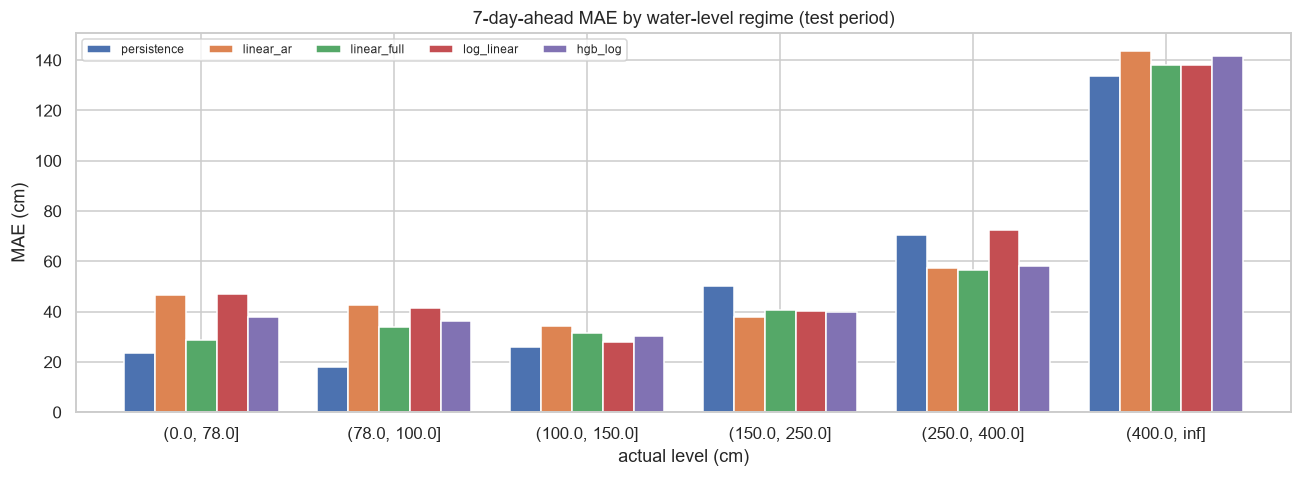

In [15]:
fig, ax = plt.subplots(figsize=(12, 4.5))
mae_reg.plot(kind="bar", ax=ax, width=0.8)
ax.set_title(f"{HORIZON}-day-ahead MAE by water-level regime (test period)")
ax.set_ylabel("MAE (cm)")
ax.set_xlabel("actual level (cm)")
ax.tick_params(axis="x", rotation=0)
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

## 7. Diagnostics

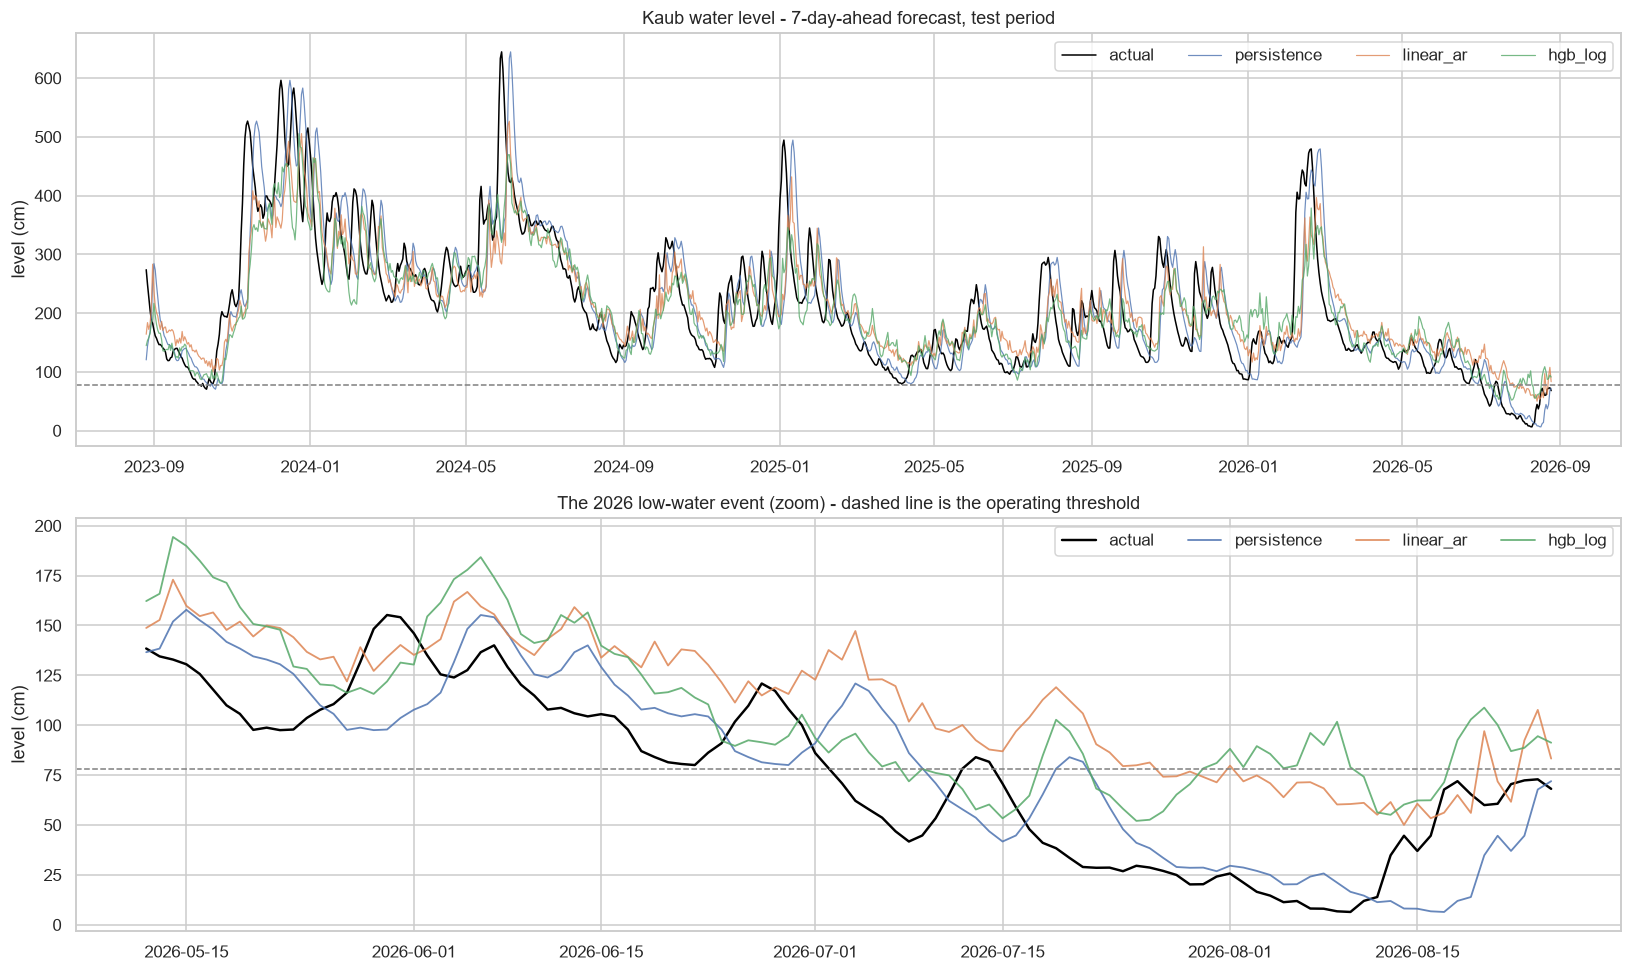

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

ax = axes[0]
ax.plot(y_te.index, y_te, lw=1.0, color="black", label="actual")
for name in ["persistence", "linear_ar", "hgb_log"]:
    ax.plot(preds[name].index, preds[name], lw=0.8, alpha=0.8, label=name)
ax.axhline(LOW_WATER_CM, ls="--", lw=1, color="grey")
ax.set_title(f"Kaub water level - {HORIZON}-day-ahead forecast, test period")
ax.set_ylabel("level (cm)")
ax.legend(ncol=4)

ax = axes[1]
low_start = y_te.idxmin() - pd.Timedelta(days=90)
zoom = y_te.loc[low_start:]
ax.plot(zoom.index, zoom, lw=1.6, color="black", label="actual")
for name in ["persistence", "linear_ar", "hgb_log"]:
    ax.plot(zoom.index, preds[name].loc[zoom.index], lw=1.2, alpha=0.85, label=name)
ax.axhline(LOW_WATER_CM, ls="--", lw=1, color="grey")
ax.set_title("The 2026 low-water event (zoom) - dashed line is the operating threshold")
ax.set_ylabel("level (cm)")
ax.legend(ncol=4)

plt.tight_layout()
plt.show()

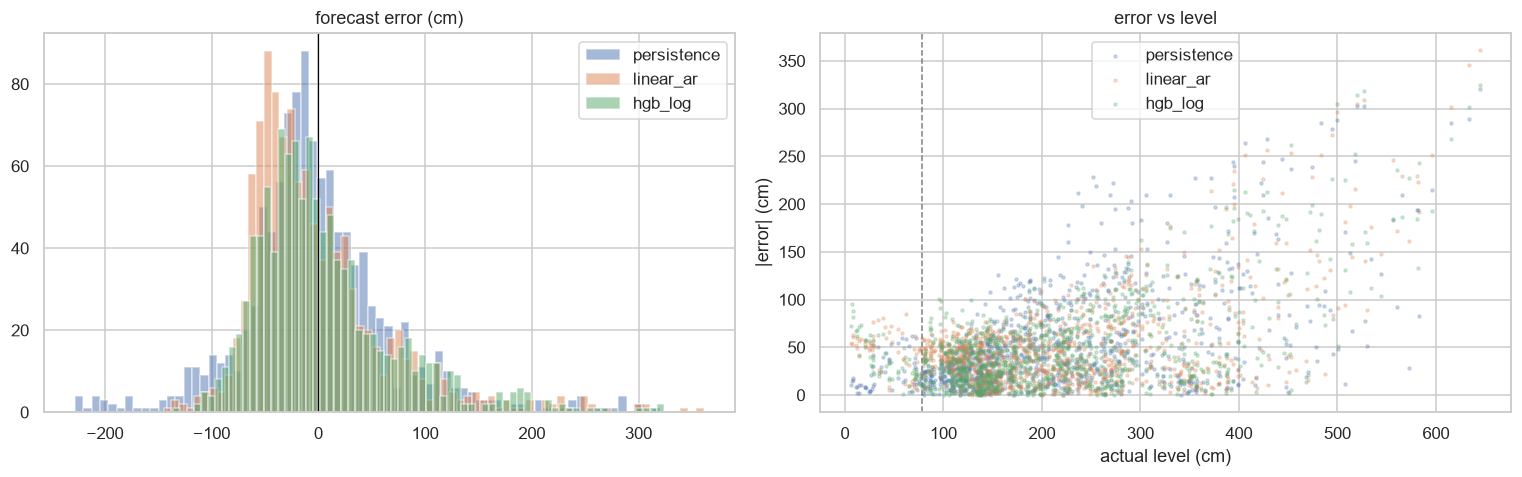

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name in ["persistence", "linear_ar", "hgb_log"]:
    err = y_te - preds[name]
    axes[0].hist(err, bins=70, alpha=0.5, label=name)
    axes[1].scatter(y_te, err.abs(), s=4, alpha=0.25, label=name)

axes[0].set_title("forecast error (cm)")
axes[0].axvline(0, color="black", lw=0.8)
axes[0].legend()
axes[1].axvline(LOW_WATER_CM, ls="--", lw=1, color="grey")
axes[1].set_xlabel("actual level (cm)")
axes[1].set_ylabel("|error| (cm)")
axes[1].set_title("error vs level")
axes[1].legend()
plt.tight_layout()
plt.show()

### 7.1 The operational question

Load planning does not need a level in centimetres, it needs to know whether the river will be
below the loading threshold in a week. Score that decision directly.

In [18]:
actual_low = y_te < LOW_WATER_CM
rows = []
for name, pred in preds.items():
    flagged = pred < LOW_WATER_CM
    tp = int((flagged & actual_low).sum())
    fp = int((flagged & ~actual_low).sum())
    fn = int((~flagged & actual_low).sum())
    rows.append({
        "model": name,
        "true_positive": tp,
        "false_positive": fp,
        "false_negative": fn,
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
    })
alarm = pd.DataFrame(rows).set_index("model")
alarm["f1"] = 2 * alarm["precision"] * alarm["recall"] / (alarm["precision"] + alarm["recall"])
print(f"predicting '{HORIZON} days from now the level will be below {LOW_WATER_CM} cm'")
print(f"actual low-water days in test: {int(actual_low.sum())} of {len(y_te)}")
alarm.round(3)

predicting '7 days from now the level will be below 78 cm'
actual low-water days in test: 57 of 1096


,true_positive,false_positive,false_negative,precision,recall,f1
model,,,,,,
persistence,41,9,16,0.820,0.719,0.766
linear_ar,25,0,32,1.000,0.439,0.610
linear_full,38,3,19,0.927,0.667,0.776
log_linear,12,0,45,1.000,0.211,0.348
hgb_log,21,3,36,0.875,0.368,0.519


A false negative is the expensive error - the barge sails loaded into water that will not carry
it. Recall is therefore the column to optimise, and `LOW_WATER_CM` should be replaced with the
operator's real limit before any of these numbers are quoted.

## 8. Feature importance

Permutation importance on the test set, scored by low-water MAE, so it answers "what does the
model rely on when the river is low" rather than "what does it rely on on an average day".

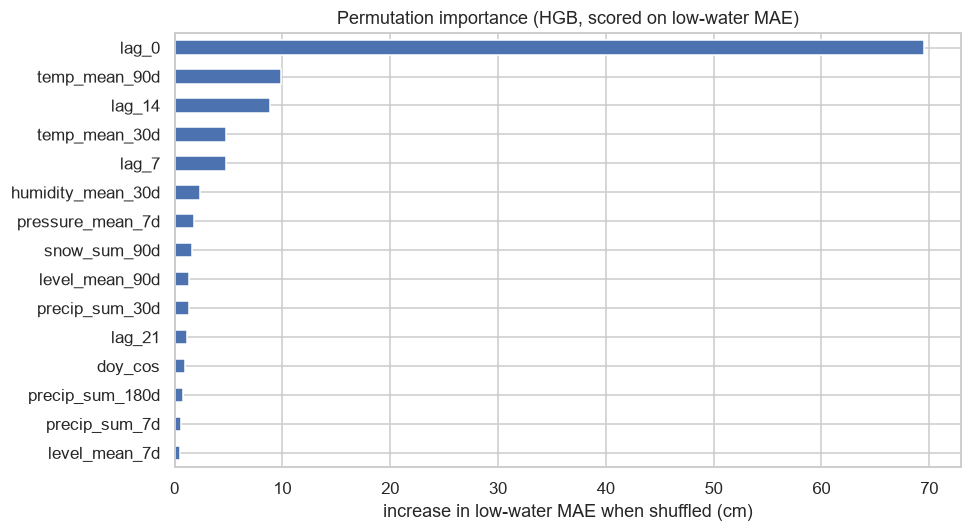

lag_0                69.510
temp_mean_90d         9.879
lag_14                8.851
temp_mean_30d         4.797
lag_7                 4.783
humidity_mean_30d     2.386
pressure_mean_7d      1.824
snow_sum_90d          1.588
level_mean_90d        1.343
precip_sum_30d        1.317
lag_21                1.179
doy_cos               0.976
precip_sum_180d       0.810
precip_sum_7d         0.619
level_mean_7d         0.532
dtype: float64

In [19]:
from sklearn.inspection import permutation_importance


def low_water_mae(estimator, X_in, y_in):
    pred = 10 ** estimator.predict(X_in) * smear_hgb
    low = y_in < LOW_WATER_CM
    if not low.any():
        return 0.0
    return -np.abs(y_in[low] - pred[low]).mean()   # negated: higher is better


imp = permutation_importance(
    hgb, X_te, y_te, scoring=low_water_mae,
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=1,
)
ranked = (
    pd.Series(imp.importances_mean, index=FULL_FEATURES)
      .sort_values(ascending=False)
      .head(15)
)

fig, ax = plt.subplots(figsize=(9, 5))
ranked.iloc[::-1].plot(kind="barh", ax=ax, color="#4c72b0")
ax.set_title("Permutation importance (HGB, scored on low-water MAE)")
ax.set_xlabel("increase in low-water MAE when shuffled (cm)")
plt.tight_layout()
plt.show()

ranked.round(3)

## 9. How far ahead is the forecast actually useful?

Section 6.1 shows every model losing to persistence below 150 cm at a 7-day horizon. Rather
than accept that as a verdict on the models, ask what it is a verdict on: the *horizon*. The
features do not depend on `HORIZON` - only the target does - so the whole comparison can be
swept cheaply across lead times.

Both metrics are reported, because they disagree and the disagreement is the point: MAE scores
the level, recall scores the decision.

In [20]:
rows = []
for h in [1, 2, 3, 5, 7, 10, 14]:
    d_h = X.join(level.shift(-h).rename("target")).dropna()
    sp = d_h.index.max() - pd.DateOffset(years=TEST_YEARS)
    tr_h = d_h.loc[: sp - pd.Timedelta(days=h)]
    te_h = d_h.loc[sp + pd.Timedelta(days=1):]

    model_h = LinearRegression().fit(tr_h[FULL_FEATURES], tr_h["target"])
    y_h = te_h["target"]
    cand = {
        "persistence": te_h["lag_0"],
        "linear_full": pd.Series(model_h.predict(te_h[FULL_FEATURES]), index=te_h.index),
    }

    low_h = y_h < LOW_WATER_CM
    row = {"horizon": h, "n_low": int(low_h.sum())}
    for name, pred in cand.items():
        flagged = pred < LOW_WATER_CM
        tp = int((flagged & low_h).sum())
        fp = int((flagged & ~low_h).sum())
        fn = int((~flagged & low_h).sum())
        precision = tp / (tp + fp) if tp + fp else np.nan
        recall = tp / (tp + fn) if tp + fn else np.nan
        row[f"{name}_MAE_low"] = (y_h - pred)[low_h].abs().mean()
        row[f"{name}_recall"] = recall
        row[f"{name}_f1"] = 2 * precision * recall / (precision + recall)
    rows.append(row)

sweep = pd.DataFrame(rows).set_index("horizon")
sweep.round(3)

,n_low,persistence_MAE_low,persistence_recall,persistence_f1,linear_full_MAE_low,linear_full_recall,linear_full_f1
horizon,,,,,,,
1,57,4.910,0.930,0.938,4.434,0.930,0.922
2,57,8.543,0.877,0.893,8.415,0.912,0.929
3,57,11.795,0.825,0.847,12.819,0.860,0.891
5,57,17.087,0.789,0.826,20.335,0.789,0.841
7,57,23.471,0.719,0.766,28.897,0.667,0.776
10,57,28.995,0.684,0.750,40.127,0.596,0.747
14,57,32.774,0.649,0.740,50.084,0.456,0.627


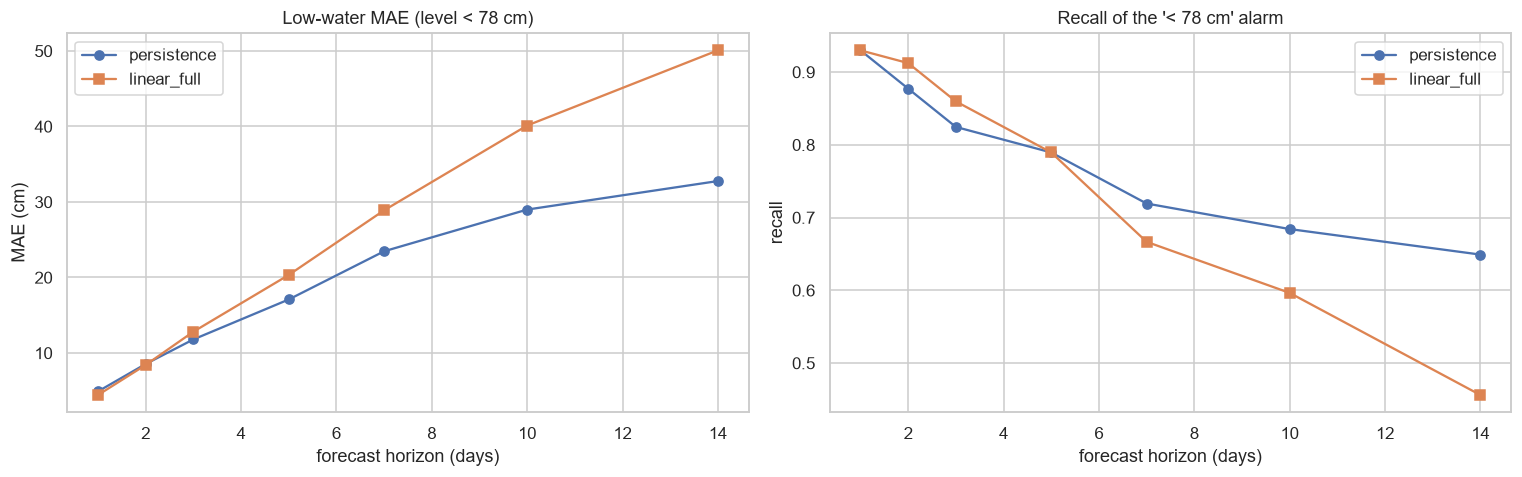

horizons where linear_full beats persistence on low-water MAE   : [1, 2]
horizons where linear_full beats persistence on low-water recall: [2, 3]


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.plot(sweep.index, sweep["persistence_MAE_low"], marker="o", label="persistence")
ax.plot(sweep.index, sweep["linear_full_MAE_low"], marker="s", label="linear_full")
ax.set_title(f"Low-water MAE (level < {LOW_WATER_CM} cm)")
ax.set_xlabel("forecast horizon (days)")
ax.set_ylabel("MAE (cm)")
ax.legend()

ax = axes[1]
ax.plot(sweep.index, sweep["persistence_recall"], marker="o", label="persistence")
ax.plot(sweep.index, sweep["linear_full_recall"], marker="s", label="linear_full")
ax.set_title(f"Recall of the '< {LOW_WATER_CM} cm' alarm")
ax.set_xlabel("forecast horizon (days)")
ax.set_ylabel("recall")
ax.legend()

plt.tight_layout()
plt.show()

wins_mae = sweep.index[sweep["linear_full_MAE_low"] < sweep["persistence_MAE_low"]].tolist()
wins_recall = sweep.index[sweep["linear_full_recall"] > sweep["persistence_recall"]].tolist()
print("horizons where linear_full beats persistence on low-water MAE   :", wins_mae)
print("horizons where linear_full beats persistence on low-water recall:", wins_recall)

## 10. Conclusions

Read against the numbers printed above, not from memory.

**At a 7-day horizon, no model here beats persistence at low water.** Section 6.1 is
unambiguous: persistence has the lowest MAE in every regime below 150 cm and above 400 cm.
That is the honest result, and it is worth more than a tuned number would be.

**Adding weather features still cut the damage in half.** `linear_full` reaches 28.9 cm MAE
below 78 cm against `linear_ar`'s 46.6 - the 03 feature set was leaving most of the available
low-water signal on the table - but it is still worse than the trivial baseline's 23.5.

**Modelling `log10(level)` did not help, which was worth finding out.** `log_linear` lands at
47.0 cm below 78 cm, no better than the raw-target AR model, so the low-water failure is not
simply a loss-scale problem. `hgb_log` at 37.7 sits between the two. The residual low-water
bias of -37 to -47 cm on all three says they are still reverting to the mean during a
recession, and a nonlinear model plus a multiplicative loss is not enough to stop it.

**The horizon, not the model class, is the binding constraint.** Section 9 shows
`linear_full` beating persistence on low-water MAE only at 1 and 2 days ahead, and on the
alarm decision - which is what load planning actually consumes - out to 3 days. Beyond that
persistence wins on recall and the learned model's confident silence becomes dangerous: at 7
days `linear_ar` has perfect precision and 0.44 recall, meaning it misses 32 of 57 low-water
days while never raising a false alarm. That is the failure mode that looks best on a
dashboard and costs the most on the river.

**Ship the alarm, not the level.** At the 7-day horizon `linear_full` scores 0.93 precision
and 0.67 recall against persistence's 0.82 and 0.72. If a recall-weighted threshold is what
the operator needs, tune the decision threshold directly on validation rather than reading it
off a point forecast.

**Caveats that bound all of the above.** The 2026 record low is outside the training range -
15 test days fall below anything ever seen - so apparent skill there is unverified. And the
upstream timezone defect in `02. eda.ipynb` still stands; it does not affect these daily
features, but it blocks any sub-daily extension.

Next steps, in order of expected value: **upstream gauge readings** (Maxau, Worms) which lead
Kaub by roughly a day and are the strongest signal not in this dataset; **quantile regression**
for a lower bound on the level rather than a point estimate, which is what a loading decision
actually needs; a **direct model per lead time**; and **sample weighting or training only on
recession periods**, to attack the mean-reversion bias head-on.